<a href="https://colab.research.google.com/github/Joaopcl03/projeto-final-bigdata/blob/main/notebooks/projeto_final_equipeN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q pyspark
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.window import Window
spark = (SparkSession.builder.appName("final")
 .master("local[*]").getOrCreate())

Nesta etapa, utilizamos o PySpark para carregar uma base de dados de corridas de táxi de Nova York, armazenada no formato Parquet.

A base contém **3.066.766 registros**, representando as corridas realizadas em janeiro de 2023. Também verificamos a estrutura das colunas e os tipos de dados.

Essa etapa é importante para conhecer o conjunto de dados e preparar as informações para as próximas análises.

In [ ]:
!wget -q https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2023-01.parquet -O /content/yellow_2023-01.parquet

#Esse comando baixa os dados públicos das corridas de táxi amarelo de Nova York referentes a janeiro de 2023.

In [ ]:
df = spark.read.parquet("/content/yellow_2023-01.parquet")
df.printSchema()
print(df.count())

root
 |-- VendorID: long (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: double (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: double (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: long (nullable = true)
 |-- DOLocationID: long (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- airport_fee: double (nullable = true)

3066766


In [ ]:
print(f"Quantidade de colunas: {len(df.columns)}")

Quantidade de colunas: 19


In [ ]:
!ls -lh /content/yellow_2023-01.parquet

-rw-r--r-- 1 root root 46M Mar 20  2023 /content/yellow_2023-01.parquet


B.3 — Limpeza dos Dados

O gráfico apresenta o processo de limpeza da base de corridas de táxi de Nova York, que inicialmente possuía 3.066.766 registros.

Durante a limpeza, verificamos que não havia valores nulos nas colunas analisadas nem registros duplicados. Em seguida, foram removidas as corridas com tarifas ou distâncias menores ou iguais a zero.

Ao final, 68.384 registros foram eliminados (2,23%), restando 2.998.382 registros válidos para análise.

Essa etapa é importante para garantir maior qualidade e confiabilidade dos dados utilizados nas próximas fases do projeto.

In [ ]:
#b3
from pyspark.sql import functions as F

# Quantidade original de registros
total = df.count()

# Remover registros com valores nulos
sem_nulos = df.dropna(
    subset=["fare_amount", "trip_distance"]
)

# Remover registros duplicados
sem_dup = sem_nulos.dropDuplicates()

# Manter somente tarifas e distâncias positivas
df_ok = sem_dup.filter(
    (F.col("fare_amount") > 0) &
    (F.col("trip_distance") > 0)
)

# Mostrar quantidade após cada etapa
print("Original:", total)
print("Sem nulos:", sem_nulos.count())
print("Sem duplicados:", sem_dup.count())
print("Valores válidos:", df_ok.count())


Original: 3066766
Sem nulos: 3066766
Sem duplicados: 3066766
Valores válidos: 2998382


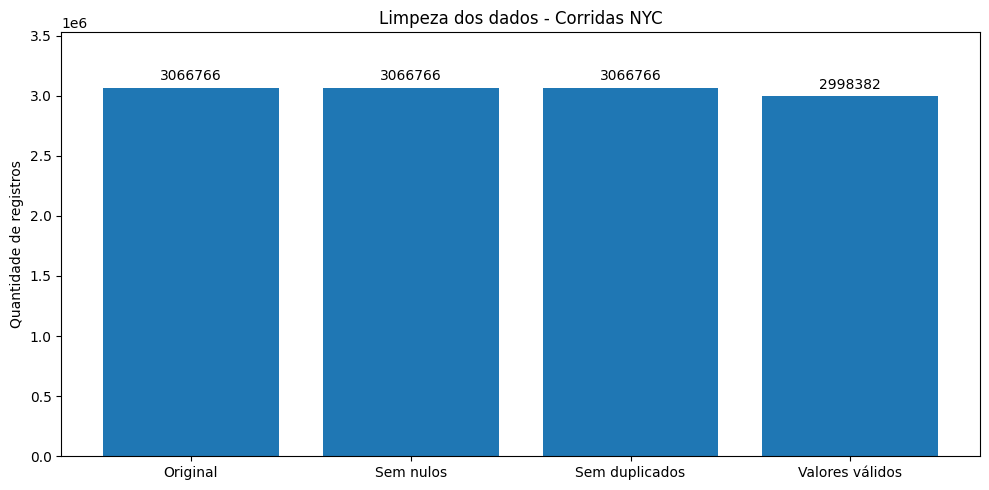

In [ ]:
import matplotlib.pyplot as plt
etapas = [
    "Original",
    "Sem nulos",
    "Sem duplicados",
    "Valores válidos"
]

quantidades = [
    total,
    sem_nulos.count(),
    sem_dup.count(),
    df_ok.count()
]

plt.figure(figsize=(10, 5))
barras = plt.bar(etapas, quantidades)

plt.bar_label(barras, fmt="%d", padding=3)
plt.title("Limpeza dos dados - Corridas NYC")
plt.ylabel("Quantidade de registros")
plt.ylim(0, max(quantidades) * 1.15)
plt.tight_layout()
plt.show()


In [ ]:

!wget -q https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv -O /content/taxi_zone_lookup.csv


B4 - Nesta etapa, utilizamos a operação **JOIN** para relacionar os dados das corridas com uma tabela de zonas geográficas de Nova York.

Em seguida, aplicamos uma função de janela (*Window*) para identificar as três zonas com maior quantidade de embarques em cada região.

Os resultados mostraram uma grande concentração de corridas em áreas como **JFK Airport, Upper East Side South e Midtown Center**.

Essa análise permite identificar as regiões de maior demanda e pode auxiliar no planejamento da distribuição de táxis pela cidade.

In [ ]:
#b4
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Carregar tabela de zonas
zonas = spark.read.csv(
    "/content/taxi_zone_lookup.csv",
    header=True,
    inferSchema=True
)

# Cruzar os dados das corridas com as zonas
juntado = df_ok.join(
    F.broadcast(zonas),
    df_ok.PULocationID == zonas.LocationID
)

# Agrupar corridas por região e zona
resumo = (
    juntado.groupBy("Borough", "Zone")
    .agg(F.count("*").alias("corridas"))
)

# Criar ranking das zonas por região
w = Window.partitionBy("Borough").orderBy(
    F.desc("corridas")
)

ranking = resumo.withColumn(
    "pos",
    F.row_number().over(w)
)

# Mostrar as 3 zonas mais movimentadas de cada região
ranking.filter("pos <= 3").show(30, truncate=False)


+-------------+---------------------------+--------+---+
|Borough      |Zone                       |corridas|pos|
+-------------+---------------------------+--------+---+
|Bronx        |Mott Haven/Port Morris     |235     |1  |
|Bronx        |Co-Op City                 |203     |2  |
|Bronx        |West Concourse             |195     |3  |
|Brooklyn     |Downtown Brooklyn/MetroTech|1464    |1  |
|Brooklyn     |Williamsburg (North Side)  |1217    |2  |
|Brooklyn     |Brooklyn Heights           |1194    |3  |
|EWR          |Newark Airport             |80      |1  |
|Manhattan    |Upper East Side South      |146152  |1  |
|Manhattan    |Upper East Side North      |136648  |2  |
|Manhattan    |Midtown Center             |133380  |3  |
|N/A          |Outside of NYC             |499     |1  |
|Queens       |JFK Airport                |154231  |1  |
|Queens       |LaGuardia Airport          |88022   |2  |
|Queens       |East Elmhurst              |12751   |3  |
|Staten Island|Bloomfield/Emers

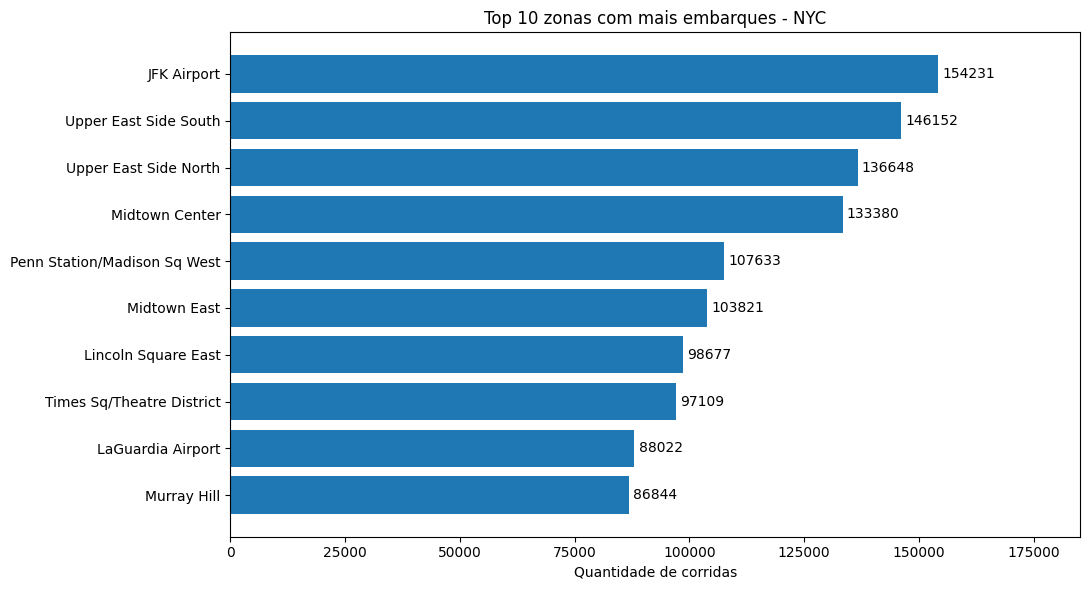

In [ ]:
import matplotlib.pyplot as plt
# Selecionar as 10 zonas com mais corridas
top10 = (
    resumo.orderBy(F.desc("corridas"))
    .limit(10)
    .toPandas()
)

top10 = top10.sort_values("corridas")

plt.figure(figsize=(11, 6))
barras = plt.barh(
    top10["Zone"],
    top10["corridas"]
)

plt.bar_label(barras, padding=3)
plt.title("Top 10 zonas com mais embarques - NYC")
plt.xlabel("Quantidade de corridas")
plt.xlim(0, top10["corridas"].max() * 1.2)
plt.tight_layout()
plt.show()


b5 - Nesta etapa, comparamos o desempenho das consultas utilizando duas técnicas de otimização do PySpark: **Cache e Broadcast**.

Com o uso do Cache, o tempo médio de execução caiu de **26,78 para 6,46 segundos**, representando uma redução de aproximadamente **75,9%**.

Já com o Broadcast, o tempo médio do JOIN diminuiu de **9,72 para 2,41 segundos**, uma redução de aproximadamente **75,2%**.

Os resultados demonstram que essas técnicas podem melhorar significativamente a eficiência do processamento de grandes volumes de dados, reduzindo o tempo necessário para executar as operações.

In [ ]:
#b5
import time
from pyspark.sql import functions as F

# Função para medir o tempo médio de execução
def medir(f, n=3):
    tempos = []

    for i in range(n):
        inicio = time.time()
        f()
        duracao = time.time() - inicio
        tempos.append(duracao)

        print(f"Execução {i+1}: {duracao:.2f} segundos")

    return sum(tempos) / n


# Garantir que a comparação comece sem cache
df_ok.unpersist(blocking=True)

# Consulta utilizada no teste
consulta = lambda d: d.groupBy("PULocationID").count().collect()

# CENÁRIO 1: SEM CACHE
print("\n--- CENÁRIO 1: SEM CACHE ---")
t1 = medir(lambda: consulta(df_ok))

# CENÁRIO 2: COM CACHE
print("\n--- CENÁRIO 2: COM CACHE ---")
df_ok.cache()
df_ok.count()  # Materializa o cache antes de medir
t2 = medir(lambda: consulta(df_ok))

# CENÁRIO 3: JOIN SEM BROADCAST
print("\n--- CENÁRIO 3: JOIN SEM BROADCAST ---")

spark.conf.set("spark.sql.autoBroadcastJoinThreshold", -1)

sem_b = lambda: df_ok.join(
    zonas,
    df_ok.PULocationID == zonas.LocationID
).count()

t3 = medir(sem_b)

# CENÁRIO 4: JOIN COM BROADCAST
print("\n--- CENÁRIO 4: JOIN COM BROADCAST ---")

com_b = lambda: df_ok.join(
    F.broadcast(zonas),
    df_ok.PULocationID == zonas.LocationID
).count()

t4 = medir(com_b)

# RESULTADOS FINAIS
print("\n========== RESULTADOS ==========")
print(f"Consulta sem cache: {t1:.2f} segundos")
print(f"Consulta com cache: {t2:.2f} segundos")
print(f"Join sem broadcast: {t3:.2f} segundos")
print(f"Join com broadcast: {t4:.2f} segundos")



--- CENÁRIO 1: SEM CACHE ---
Execução 1: 29.88 segundos
Execução 2: 24.28 segundos
Execução 3: 23.58 segundos

--- CENÁRIO 2: COM CACHE ---
Execução 1: 4.57 segundos
Execução 2: 5.93 segundos
Execução 3: 4.09 segundos

--- CENÁRIO 3: JOIN SEM BROADCAST ---
Execução 1: 9.51 segundos
Execução 2: 7.49 segundos
Execução 3: 8.61 segundos

--- CENÁRIO 4: JOIN COM BROADCAST ---
Execução 1: 2.20 segundos
Execução 2: 1.84 segundos
Execução 3: 1.80 segundos

========== RESULTADOS ==========
Consulta sem cache: 25.92 segundos
Consulta com cache: 4.86 segundos
Join sem broadcast: 8.54 segundos
Join com broadcast: 1.94 segundos


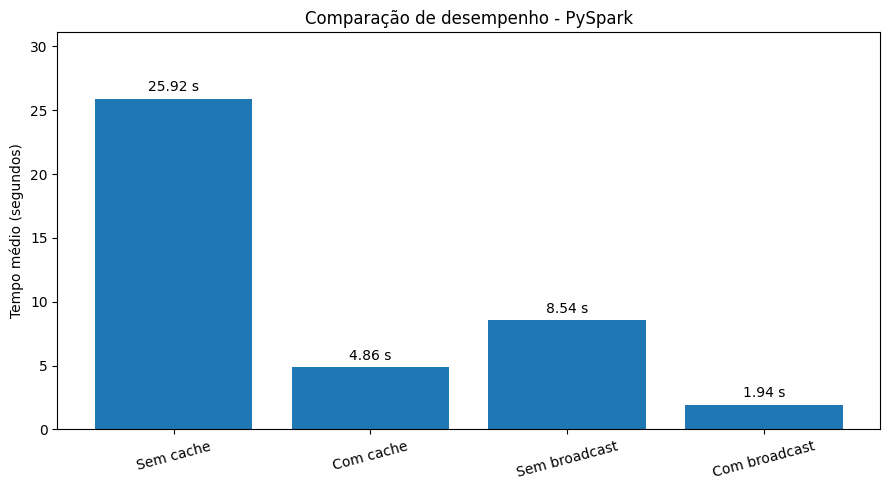

Redução com cache: 81.23%
Redução com broadcast: 77.23%


In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

cenarios = [
    "Sem cache", "Com cache",
    "Sem broadcast", "Com broadcast"
]
tempos = [t1, t2, t3, t4]

barras = ax.bar(cenarios, tempos)
ax.bar_label(barras, fmt="%.2f s", padding=3)

ax.set_title("Comparação de desempenho - PySpark")
ax.set_ylabel("Tempo médio (segundos)")
ax.set_ylim(0, max(tempos) * 1.2)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print(f"Redução com cache: {(1-t2/t1)*100:.2f}%")
print(f"Redução com broadcast: {(1-t4/t3)*100:.2f}%")


B.6 — Armazenamento em Parquet Particionado

Nesta etapa, os dados tratados foram armazenados no formato Parquet, utilizando o mês das corridas como critério de particionamento.

O gráfico apresenta a quantidade de registros distribuídos entre as partições mensais identificadas na base.

O particionamento permite que o Spark consulte apenas os arquivos correspondentes aos meses necessários, evitando a leitura de dados de outros períodos e podendo melhorar o desempenho das consultas.

Essa técnica é importante no processamento de grandes volumes de dados, pois contribui para a organização e a eficiência do armazenamento e da leitura.

In [ ]:

from pyspark.sql import functions as F

# B.6 - GRAVAR EM PARQUET PARTICIONADO

# Criar uma coluna com o mês de cada corrida
saida = df_ok.withColumn(
    "mes",
    F.month("tpep_pickup_datetime")
)

# Salvar os dados em Parquet, particionados por mês
saida.write.mode("overwrite").partitionBy("mes").parquet(
    "/content/saida"
)

print("Dados salvos em Parquet particionado!")

# Ler os dados salvos
dados_particionados = spark.read.parquet("/content/saida")

# Selecionar somente os registros de janeiro
um_mes = dados_particionados.filter(F.col("mes") == 1)

# Mostrar quantidade de registros de janeiro
print("Registros de janeiro:", um_mes.count())

# Mostrar os primeiros 5 registros
um_mes.show(5)


Dados salvos em Parquet particionado!
Registros de janeiro: 2998340
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+---+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|airport_fee|mes|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+---+
|       2| 2023-01-01 00:30:37|  2023-01-01 00:33:52|            2.0|         0.44|       1.0|             

In [ ]:

# Verificar as pastas criadas
!ls -lh /content/saida/

# Verificar os arquivos da partição de janeiro
!ls -lh /content/saida/mes=1/


total 60K
drwxr-xr-x 2 root root  48K Nov 15 17:56 'mes=1'
drwxr-xr-x 2 root root 4.0K Nov 15 17:56 'mes=10'
drwxr-xr-x 2 root root 4.0K Nov 15 17:56 'mes=12'
drwxr-xr-x 2 root root 4.0K Nov 15 17:56 'mes=2'
-rw-r--r-- 1 root root    0 Nov 15 17:56  _SUCCESS
total 72M
-rw-r--r-- 1 root root 360K Nov 15 17:56 part-00000-4bcace18-ccbf-4e35-aca8-66383b733b99.c000.snappy.parquet
-rw-r--r-- 1 root root 364K Nov 15 17:56 part-00001-4bcace18-ccbf-4e35-aca8-66383b733b99.c000.snappy.parquet
-rw-r--r-- 1 root root 363K Nov 15 17:56 part-00002-4bcace18-ccbf-4e35-aca8-66383b733b99.c000.snappy.parquet
-rw-r--r-- 1 root root 364K Nov 15 17:56 part-00003-4bcace18-ccbf-4e35-aca8-66383b733b99.c000.snappy.parquet
-rw-r--r-- 1 root root 359K Nov 15 17:56 part-00004-4bcace18-ccbf-4e35-aca8-66383b733b99.c000.snappy.parquet
-rw-r--r-- 1 root root 363K Nov 15 17:56 part-00005-4bcace18-ccbf-4e35-aca8-66383b733b99.c000.snappy.parquet
-rw-r--r-- 1 root root 363K Nov 15 17:56 part-00006-4bcace18-ccbf-4e35-aca8-6

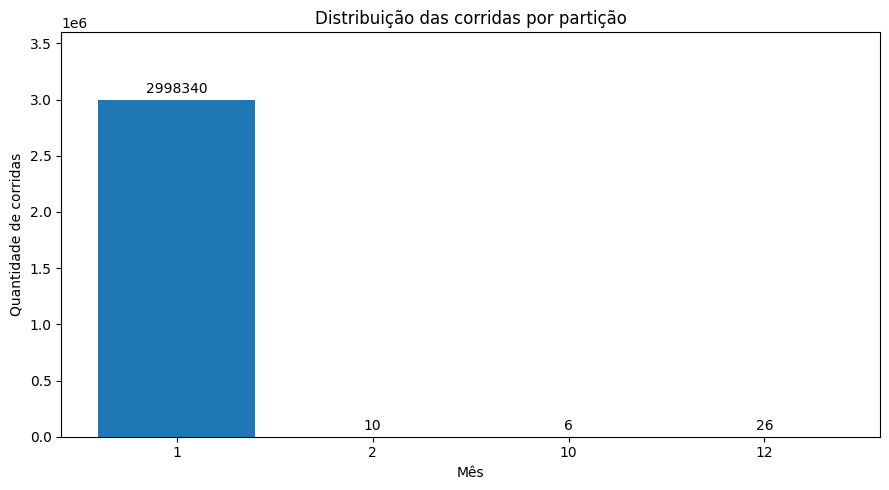

In [ ]:
import matplotlib.pyplot as plt

# Quantidade de corridas por partição
dados_grafico = (
    dados_particionados
    .groupBy("mes")
    .count()
    .orderBy("mes")
    .toPandas()
)

plt.figure(figsize=(9, 5))

barras = plt.bar(
    dados_grafico["mes"].astype(str),
    dados_grafico["count"]
)

plt.bar_label(barras, fmt="%d", padding=3)
plt.title("Distribuição das corridas por partição")
plt.xlabel("Mês")
plt.ylabel("Quantidade de corridas")
plt.ylim(0, dados_grafico["count"].max() * 1.2)
plt.tight_layout()
plt.show()
